# Predicting Monthly Cash Earnings of Rwandan Youth (Ages 18–35)

## Mission & Problem Statement
This notebook supports **SkillBridge**, a digital platform addressing Rwanda's youth skills-to-employment gap (46% unemployment among secondary completers aged 18–35, NISR 2024; 70% graduate skills mismatch, World Bank 2024) by validating practical skills for both degree and non-degree/TVET youth and matching verified talent to jobs.

- **Target variable:** `monthly_income_k_rwf` (`cash / 1000`), expected monthly cash earnings in thousands of Rwandan Francs (RWF).
- **Who uses the prediction and what for:** Young Rwandan job seekers (aged 18–35, including secondary completers and TVET trainees) and SkillBridge career advisors/employers use these predictions to benchmark fair monthly pay for a given skill, education, experience, location, and job profile—helping youth avoid underpaying informal offers and see the expected earnings return of TVET, digital access, and written contracts.
- **Dataset source:** Rwanda Labour Force Survey 2022 (`RW_LFS2022.dta`), published by the National Institute of Statistics of Rwanda ([NISR Microdata Catalog #104](https://microdata.statistics.gov.rw/index.php/catalog/104)).

## 1. Import Libraries
`Matplotlib`/`Seaborn` for visualization, `scikit-learn` for preprocessing and regression modeling, and `joblib` for model serialization.

In [1]:
from pathlib import Path
from IPython.display import display
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadstat
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")

## 2. Load and Inspect the Raw Survey Dataset
Place `RW_LFS2022.dta` inside `summative/linear_regression/data/`. We load the raw survey records alongside NISR metadata labels.

In [2]:
candidate_paths = [
    Path("data/RW_LFS2022.dta"),
]

data_path = next((p for p in candidate_paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Dataset file under data is not found")

df_raw, meta = pyreadstat.read_dta(data_path, apply_value_formats=False, user_missing=True)
val_labels = meta.variable_value_labels
print(f"Loaded {data_path}: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Value-label maps loaded: {len(val_labels)}")

Loaded data\RW_LFS2022.dta: 70,424 rows x 239 columns
Value-label maps loaded: 161


### Inspect Target Population Counts (Youth Ages 18-35, Employed with Cash Earnings)
We filter to employed youth (`A04` between 18 and 35, `status1 == 1`) who reported numeric monthly cash earnings (`cash`).

In [3]:
age = pd.to_numeric(df_raw["A04"], errors="coerce")
status = pd.to_numeric(df_raw["status1"], errors="coerce")
cash = pd.to_numeric(df_raw["cash"], errors="coerce")

youth_paid = df_raw[age.between(18, 35) & (status == 1) & cash.notna()].copy()
youth_paid["cash_num"] = pd.to_numeric(youth_paid["cash"], errors="coerce")

print(f"All survey records:                    {len(df_raw):,}")
print(f"Employed youth (18-35) with cash pay:  {len(youth_paid):,}")
print(f"Records > 500,000 RWF (top ~1.1%):     {(youth_paid['cash_num'] > 500_000).sum():,}")
print(f"Records <= 500,000 RWF (modeling set): {(youth_paid['cash_num'] <= 500_000).sum():,}")

All survey records:                    70,424
Employed youth (18-35) with cash pay:  7,336
Records > 500,000 RWF (top ~1.1%):     81
Records <= 500,000 RWF (modeling set): 7,255


## 3. Exploratory Data Analysis (EDA)
### Plot 1: Monthly Cash Income Distribution (Before & After Outlier Cap)
Before selecting features or training models, we check the raw distribution of `cash` among employed youth aged 18–35.

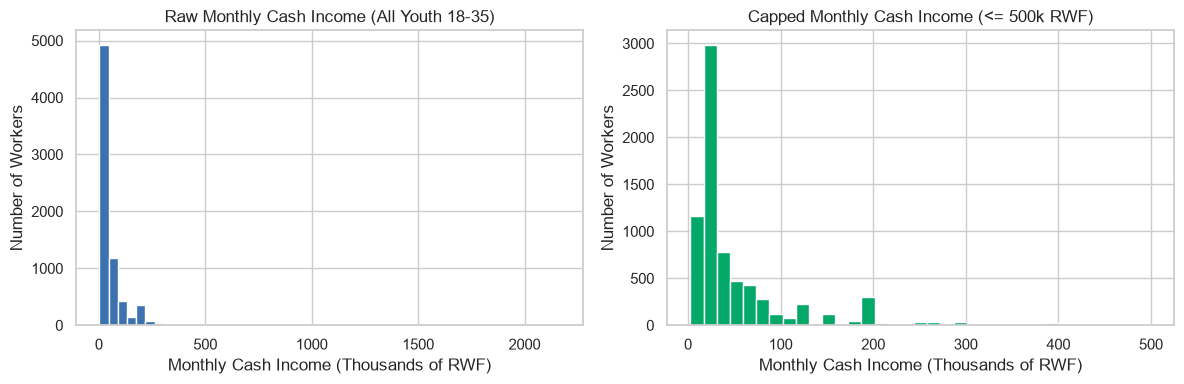

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(youth_paid["cash_num"] / 1000, bins=50, color="#3C72B0", edgecolor="white")
axes[0].set_title("Raw Monthly Cash Income (All Youth 18-35)")
axes[0].set_xlabel("Monthly Cash Income (Thousands of RWF)")
axes[0].set_ylabel("Number of Workers")

capped = youth_paid.loc[youth_paid["cash_num"] <= 500_000, "cash_num"] / 1000
axes[1].hist(capped, bins=35, color="#04A868", edgecolor="white")
axes[1].set_title("Capped Monthly Cash Income (<= 500k RWF)")
axes[1].set_xlabel("Monthly Cash Income (Thousands of RWF)")
axes[1].set_ylabel("Number of Workers")

plt.tight_layout()
plt.show()

**What Plot 1 shows and our decision:** Raw monthly earnings are heavily right-skewed, stretching past 2,000,000 RWF for just ~1.1% of observations (`81` out of `7,336` youth workers). Because MSE squares large errors, those extreme outliers would dominate training and destabilize gradient descent, so we cap the target at `<= 500,000 RWF` (`<= 500` thousand RWF) and express it as `monthly_income_k_rwf`.

## 4. Feature Engineering & Column Selection

Out of the `239` raw NISR columns, we curate **13 clean, domain-aligned predictors** (5 numeric + 8 categorical) matching SkillBridge's user profile and drop the rest for clear reasons:

- **Dropped survey IDs & metadata:** `PSU_NO`, `QH_NO`, `HHID`, `pid`, `LFS_year`, `weight2` are sampling identifiers, not worker attributes.
- **Dropped target-leaking or post-payroll fields:** `D12`, `D12A`, `D13`, `D17`, `intcash`, `hr_cash`, `hr_cshmain`, `D10D` (PAYE tax), and `D09A`/`D09B` (employer social security/health deductions) directly reveal or depend on realized salary.
- **Dropped high-missingness & redundant encodings:** Secondary-job fields (`C11B`–`C13B`, >98% missing), non-applicable modules (`A16Y`–`A23`, `G01`–`G07`), and duplicate education/age recodes (`attained`, `B02A`, `TVT`, `age5`, `age10`) were dropped to avoid multicollinearity and keep the model practical for mobile input.
- **Selected numeric features (5):** `age` (`A04`), `years_schooling` (`indb1`), `experience_years` (`D24A`), `weekly_hours` (`C11A`), `household_size` (`hhsize`).
- **Selected categorical features (8):** `sex` (`A01`), `province`, `urban_rural` (`Code_UR`), `education_track` (`TVT2`), `internet_use` (`B19`), `sector` (`main_sect`), `occupation_group` (`indd01`), `contract_basis` (`D06`).

In [5]:
def map_labels(series, col_name):
    mapped = pd.to_numeric(series, errors="coerce").map(val_labels.get(col_name, {}))
    return mapped.astype(str).str.strip().str.replace("_", " ", regex=False)

sub = youth_paid[youth_paid["cash_num"].between(1, 500_000)].copy()

df_clean = pd.DataFrame({
    "age": pd.to_numeric(sub["A04"], errors="coerce"),
    "years_schooling": pd.to_numeric(sub["indb1"], errors="coerce"),
    "experience_years": pd.to_numeric(sub["D24A"], errors="coerce"),
    "weekly_hours": pd.to_numeric(sub["C11A"], errors="coerce"),
    "household_size": pd.to_numeric(sub["hhsize"], errors="coerce"),
    "sex": map_labels(sub["A01"], "A01"),
    "province": map_labels(sub["province"], "province"),
    "urban_rural": map_labels(sub["Code_UR"], "Code_UR"),
    "education_track": map_labels(sub["TVT2"], "TVT2"),
    "internet_use": map_labels(sub["B19"], "B19").replace({"Don't Know": np.nan}),
    "sector": map_labels(sub["main_sect"], "main_sect"),
    "occupation_group": map_labels(sub["indd01"], "indd01"),
    "contract_basis": map_labels(sub["D06"], "D06"),
    "monthly_income_k_rwf": sub["cash_num"] / 1000.0,
}).dropna().reset_index(drop=True)

assert len(df_clean) > 0, "df_clean is empty: check val_labels and column names"

print(f"Clean modeling dataset: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
df_clean.head(5)

Clean modeling dataset: 7,231 rows x 14 columns


,age,years_schooling,experience_years,weekly_hours,household_size,sex,province,urban_rural,education_track,internet_use,sector,occupation_group,contract_basis,monthly_income_k_rwf
0,25,16.0,4,70.0,3,Male,Kigali city,Urban,Completed TVET,Yes,Industry,Professionals,Written contract,70.0
1,24,12.0,3,30.0,5,Male,Kigali city,Urban,Completed TVET,Yes,Industry,Craft and related trades workers,Oral agreement,182.0
2,22,8.0,0,70.0,5,Female,Kigali city,Urban,Completed general,No,Services,Elementary occupations,Oral agreement,15.0
3,22,8.0,0,70.0,4,Female,Kigali city,Urban,Completed general,No,Services,Service and sales workers,Oral agreement,26.0
4,33,18.0,8,40.0,1,Male,Kigali city,Urban,Completed general,Yes,Services,Professionals,Written contract,200.0


### Plot 2: Correlation Heatmap (Numeric Features & Target)
We check how strongly each numeric variable relates to monthly earnings and inspect for collinearity among numeric predictors.

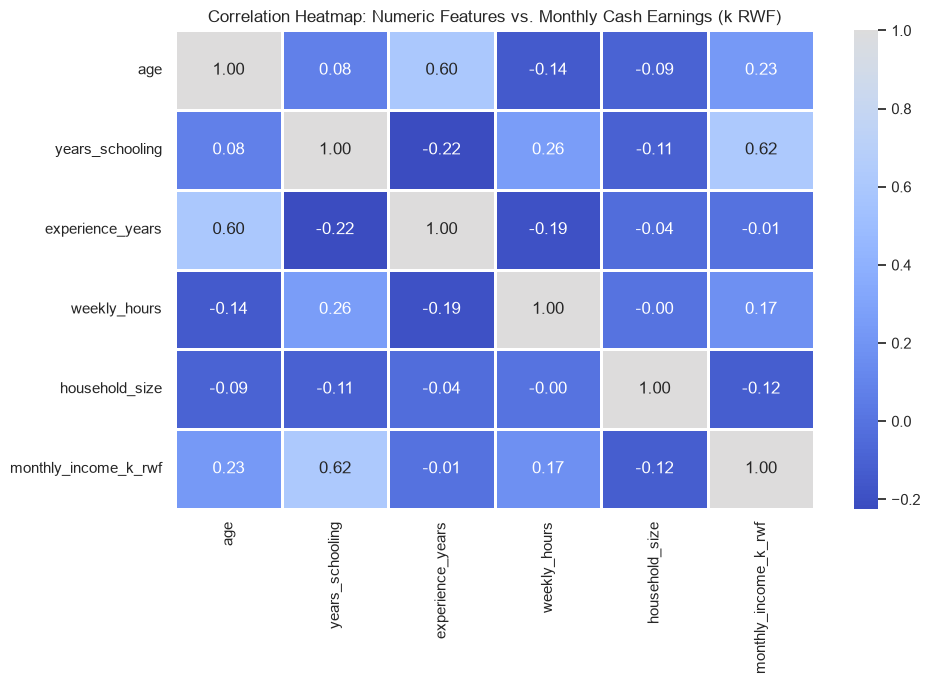

In [6]:
numeric_cols = ["age", "years_schooling", "experience_years", "weekly_hours", "household_size"]
corr_matrix = df_clean[numeric_cols + ["monthly_income_k_rwf"]].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=1, linewidths=0.9)
plt.title("Correlation Heatmap: Numeric Features vs. Monthly Cash Earnings (k RWF)")
plt.tight_layout()
plt.show()

**What Plot 2 shows and our decision:** `years_schooling` has by far the strongest positive correlation with monthly cash earnings ($r = +0.62$), followed by `age` ($r = +0.23$) and `weekly_hours` ($r = +0.17$), whereas `household_size` correlates negatively ($r = -0.12$). `age` and `experience_years` show a moderate positive correlation ($r = +0.60$), which is well below severe multicollinearity thresholds (`0.85+`), so we retain all five numeric features and select `years_schooling` for the one-feature scatter plots.

### Plot 3: Earnings Across Education Track and Contract Type
Next, we visualize how key categorical factors aligned with SkillBridge TVET/general schooling and formal written contracts—affect youth earnings.

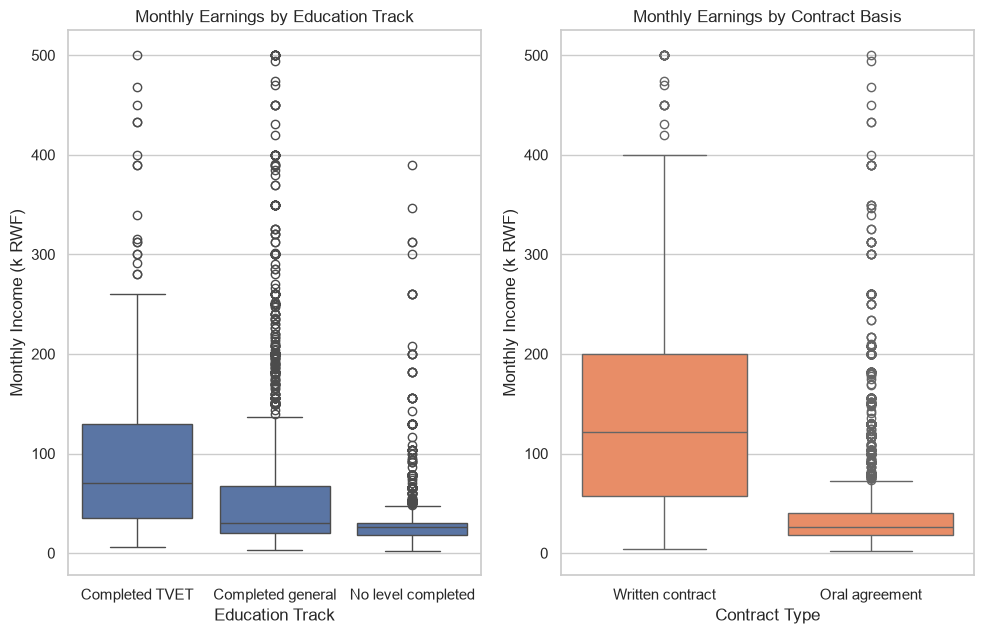

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6.5))

sns.boxplot(data=df_clean, x="education_track", y="monthly_income_k_rwf", ax=axes[0], color="#4E72B0")
axes[0].set_title("Monthly Earnings by Education Track")
axes[0].set_xlabel("Education Track")
axes[0].set_ylabel("Monthly Income (k RWF)")

sns.boxplot(data=df_clean, x="contract_basis", y="monthly_income_k_rwf", ax=axes[1], color="#FD8452")
axes[1].set_title("Monthly Earnings by Contract Basis")
axes[1].set_xlabel("Contract Type")
axes[1].set_ylabel("Monthly Income (k RWF)")

plt.tight_layout()
plt.show()

**What Plot 3 shows and our decision:** Youth who completed TVET or general schooling earn noticeably higher median and upper-quartile incomes than those with no completed level, and workers on written contracts earn dramatically more than those on oral agreements. These clear subgroup differences confirm that categorical features carry major signal alongside years of schooling, so we encode all 8 categorical variables into numeric indicator columns.

## 5. Categorical Encoding, Train/Test Split, and Standardization

To prevent data leakage:
1. We split the clean dataset into **80% training (`X_train, y_train`)** and **20% test (`X_test, y_test`)** first.
2. We build a `ColumnTransformer` that converts the 8 categorical columns to numeric binary indicators via `OneHotEncoder(handle_unknown="ignore")` and standardizes the 5 numeric features with `StandardScaler()`.
3. We fit the preprocessor on **`X_train` only**, then transform both `X_train` and `X_test`.

In [8]:
categorical_cols = [
    "sex", "province", "urban_rural", "education_track",
    "internet_use", "sector", "occupation_group", "contract_basis",
]
X = df_clean[numeric_cols + categorical_cols]
y = df_clean["monthly_income_k_rwf"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical_cols),
])

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
print(f"Train shape: {X_train_proc.shape} | Test shape: {X_test_proc.shape}")

Train shape: (5784, 33) | Test shape: (1447, 33)


## 6. Model 1: Tuning `SGDRegressor` and Plotting the Epoch Loss Curve

We tune `SGDRegressor` across learning rates (`eta0`), L2 regularization strengths (`alpha`), and epoch counts (`n_epochs`). Because scikit-learn does not record per-epoch MSE automatically, we train with `partial_fit` inside a loop and record both Train MSE and Test MSE after every epoch.

In [9]:
def train_sgd_epochs(X_tr, y_tr, X_te, y_te, eta0, alpha, n_epochs):
    sgd = SGDRegressor(loss="squared_error", penalty="l2", alpha=alpha,
                       learning_rate="invscaling", eta0=eta0, power_t=0.25, random_state=42)
    rng = np.random.default_rng(42)
    tr_hist, te_hist = [], []
    for _ in range(n_epochs):
        idx = rng.permutation(len(X_tr))
        sgd.partial_fit(X_tr[idx], y_tr.iloc[idx])
        tr_hist.append(mean_squared_error(y_tr, sgd.predict(X_tr)))
        te_hist.append(mean_squared_error(y_te, sgd.predict(X_te)))
    return sgd, tr_hist, te_hist

tuning_grid = [
    (0.001, 0.0001, 50), (0.005, 0.001, 80), (0.01, 0.0001, 50),
    (0.01, 0.001, 50), (0.01, 0.01, 50), (0.05, 0.001, 50), (0.01, 0.0001, 100),
]

tuning_rows = []
for eta0, alpha, epochs in tuning_grid:
    _, tr_h, te_h = train_sgd_epochs(X_train_proc, y_train, X_test_proc, y_test, eta0, alpha, epochs)
    tuning_rows.append({"eta0": eta0, "alpha": alpha, "epochs": epochs, "train_mse": round(tr_h[-1], 2), "test_mse": round(te_h[-1], 2)})

tuning_df = pd.DataFrame(tuning_rows).sort_values("test_mse").reset_index(drop=True)
tuning_df

,eta0,alpha,epochs,train_mse,test_mse
0,0.010,0.0001,100,1742.78,1605.60
1,0.005,0.0010,80,1748.35,1609.63
2,0.010,0.0010,50,1747.33,1620.95
3,0.010,0.0001,50,1746.18,1621.79
4,0.010,0.0100,50,1765.49,1623.82
5,0.050,0.0010,50,1757.29,1642.94
6,0.001,0.0001,50,1823.11,1650.99


### Plot 4: `SGDRegressor` Loss Curve (Train MSE vs. Test MSE per Epoch)
Using the best-tuned configuration from the table above (`eta0=0.01`, `alpha=0.0001`, `epochs=100`), we record and plot both Train MSE and Test MSE across epochs.

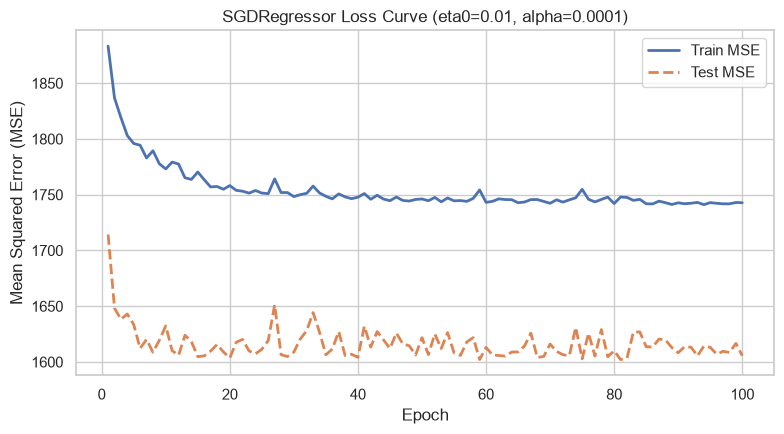

In [10]:
best_cfg = tuning_df.iloc[0]
sgd_model, sgd_train_loss, sgd_test_loss = train_sgd_epochs(
    X_train_proc, y_train, X_test_proc, y_test,
    eta0=float(best_cfg["eta0"]), alpha=float(best_cfg["alpha"]), n_epochs=int(best_cfg["epochs"])
)

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(sgd_train_loss) + 1), sgd_train_loss, label="Train MSE", linewidth=2)
plt.plot(range(1, len(sgd_test_loss) + 1), sgd_test_loss, label="Test MSE", linewidth=2, linestyle="--")
plt.title(f"SGDRegressor Loss Curve (eta0={best_cfg['eta0']}, alpha={best_cfg['alpha']})")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.tight_layout()
plt.show()

**What the tuning & loss curve show:** Both Train MSE and Test MSE drop sharply in the first 15 epochs and flatten smoothly without overfitting (the test split happens to have slightly lower variance than the train split, so Test MSE stays slightly below Train MSE). A smaller learning rate (`eta0=0.001`) underfits within 50 epochs (`1650.99`), an overly large step (`eta0=0.05`) adds oscillation (`1642.94`), and heavy regularization (`alpha=0.01`) adds bias (`1623.82`), whereas `eta0=0.01`, `alpha=0.0001`, `epochs=100` achieves the lowest SGD test loss (`1605.60`).

## 7. Train and Compare All Four Regression Models

We evaluate all four required scikit-learn models on the exact same preprocessed train and test sets using Mean Squared Error (MSE):
1. `SGDRegressor` (linear regression via gradient descent, tuned above)
2. `LinearRegression` (closed-form OLS linear regression)
3. `DecisionTreeRegressor` (single non-linear tree, regularized with `max_depth=7, min_samples_leaf=15`)
4. `RandomForestRegressor` (bagged ensemble of 200 trees, `max_depth=12, min_samples_leaf=5`)

In [11]:
candidates = {
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(max_depth=7, min_samples_leaf=15, random_state=42),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1),
}

results = [{
    "Model": "SGDRegressor (tuned)",
    "Train MSE": mean_squared_error(y_train, sgd_model.predict(X_train_proc)),
    "Test MSE": mean_squared_error(y_test, sgd_model.predict(X_test_proc)),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, sgd_model.predict(X_test_proc))),
    "Test R2": r2_score(y_test, sgd_model.predict(X_test_proc)),
}]

fitted_models = {"SGDRegressor (tuned)": sgd_model}
for name, est in candidates.items():
    est.fit(X_train_proc, y_train)
    fitted_models[name] = est
    tr_mse = mean_squared_error(y_train, est.predict(X_train_proc))
    te_mse = mean_squared_error(y_test, est.predict(X_test_proc))
    results.append({"Model": name, "Train MSE": tr_mse, "Test MSE": te_mse,
                    "Test RMSE": np.sqrt(te_mse), "Test R2": r2_score(y_test, est.predict(X_test_proc))})

comparison_df = pd.DataFrame(results).sort_values("Test MSE").reset_index(drop=True)
comparison_df.round(2)

,Model,Train MSE,Test MSE,Test RMSE,Test R2
0,RandomForestRegressor,909.04,1335.96,36.55,0.65
1,DecisionTreeRegressor,1395.16,1500.01,38.73,0.61
2,SGDRegressor (tuned),1742.78,1605.60,40.07,0.58
3,LinearRegression,1739.61,1613.33,40.17,0.58


**Best Model Selection:** **`RandomForestRegressor` is the best model** because it achieves the **lowest Test MSE (`1335.96`)**—corresponding to a Test RMSE of `36.55k RWF` and $R^2 = 0.65$—clearly beating `DecisionTreeRegressor` (`1500.01`), `SGDRegressor` (`1605.60`), and `LinearRegression` (`1613.33`).

**Why `RandomForestRegressor` fits this dataset best:** Youth earnings in Rwanda combine continuous relationships (years of schooling and weekly hours) with strong non-linear interactions (e.g., education/TVET credentials paired with formal written contracts and urban/Kigali service occupations versus informal rural agriculture). Linear models cannot represent those interaction jumps, and a single decision tree overfits high-variance pockets, whereas averaging 200 depth-limited trees smooths variance while capturing non-linear structure.

### Most Influential Features
Inspecting feature importances from the winning Random Forest confirms which variables drive predictions most.

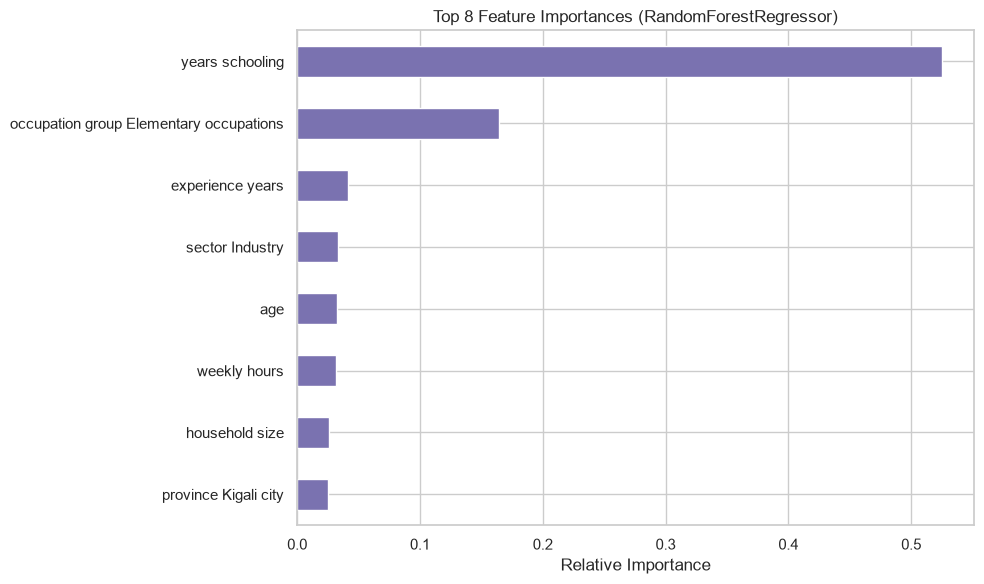

In [12]:
clean_names = [n.split("__", 1)[-1].replace("_", " ") for n in preprocessor.get_feature_names_out()]
importances = pd.Series(fitted_models["RandomForestRegressor"].feature_importances_, index=clean_names)
top_features = importances.sort_values(ascending=False).head(8)

plt.figure(figsize=(10, 6))
top_features.sort_values().plot(kind="barh", color="#7A72B0")
plt.title("Top 8 Feature Importances (RandomForestRegressor)")
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()

## 8. Scatter Plots: Before and After Fitting a 1-Feature Linear Regression

Following the assignment specification, we plot the single feature most correlated with monthly earnings (`years_schooling`, $r = +0.62$) against `monthly_income_k_rwf` **before** and **after** overlaying a one-feature `LinearRegression` line.

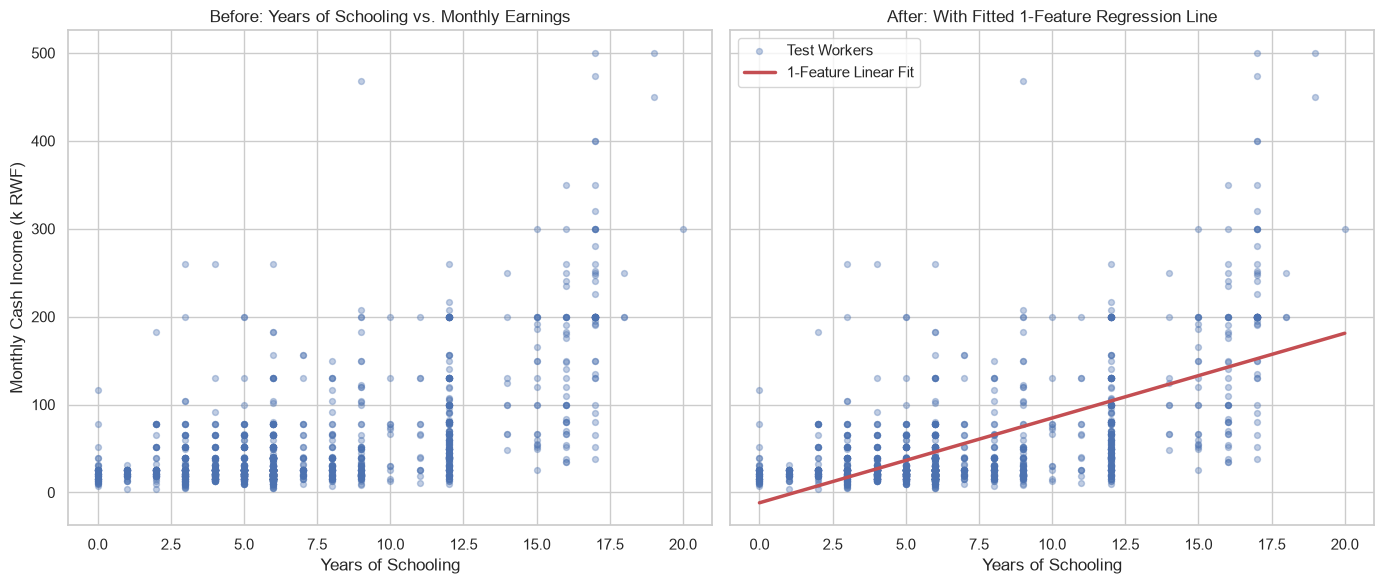

In [13]:
one_feat_lr = LinearRegression()
one_feat_lr.fit(X_train[["years_schooling"]], y_train)
x_line = np.linspace(df_clean["years_schooling"].min(), df_clean["years_schooling"].max(), 100).reshape(-1, 1)
y_line = one_feat_lr.predict(pd.DataFrame(x_line, columns=["years_schooling"]))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

axes[0].scatter(X_test["years_schooling"], y_test, alpha=0.35, s=18, color="#4C72B0")
axes[0].set_title("Before: Years of Schooling vs. Monthly Earnings")
axes[0].set_xlabel("Years of Schooling")
axes[0].set_ylabel("Monthly Cash Income (k RWF)")

axes[1].scatter(X_test["years_schooling"], y_test, alpha=0.35, s=18, color="#4C72B0", label="Test Workers")
axes[1].plot(x_line, y_line, color="#C44E52", linewidth=2.5, label="1-Feature Linear Fit")
axes[1].set_title("After: With Fitted 1-Feature Regression Line")
axes[1].set_xlabel("Years of Schooling")
axes[1].legend()

plt.tight_layout()
plt.show()

**What the before/after scatter plots show:** Higher schooling clearly shifts youth earnings upward, and the 1-feature linear fit captures that positive slope. However, wide vertical spread at every schooling level (e.g., 12–16 years) shows why additional features like occupation, contract type, TVET, and province—modeled jointly by our Random Forest—are essential for accurate pay predictions.

## 9. Save Best Model Pipeline and Single-Row Prediction Function

We wrap the `preprocessor` and winning `RandomForestRegressor` into a single scikit-learn `Pipeline` fitted on `(X_train, y_train)` and save it to `../API/best_model.pkl` using `joblib` so Task 2's FastAPI service can load it directly.

In [14]:
best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1)),
])
best_pipeline.fit(X_train, y_train)

model_path = Path("../API/best_model.pkl")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(best_pipeline, model_path)

df_clean.to_csv("../API/training_data.csv", index=False)

verified_mse = mean_squared_error(y_test, best_pipeline.predict(X_test))
print(f"Saved pipeline to {model_path} ({model_path.stat().st_size / 1e6:.2f} MB) | Verified Test MSE: {verified_mse:.2f}")

Saved pipeline to ..\API\best_model.pkl (10.24 MB) | Verified Test MSE: 1335.96


### Single-Row Prediction Function (Reused in Task 2)
We define a reusable helper that loads `best_model.pkl` from disk and predicts monthly earnings for a single row from `X_test`.

In [15]:
def predict_monthly_income(row_df, model_file=Path("../API/best_model.pkl")):
    loaded_model = joblib.load(model_file)
    return float(loaded_model.predict(row_df)[0])

sample_row = X_test.iloc[[0]]
actual_income = float(y_test.iloc[0])
predicted_income = predict_monthly_income(sample_row)

display(sample_row)
print(f"Predicted Monthly Earnings: {predicted_income:.2f}k RWF ({predicted_income * 1000:,.0f} RWF)")
print(f"Actual Monthly Earnings:    {actual_income:.2f}k RWF ({actual_income * 1000:,.0f} RWF)")

,age,years_schooling,experience_years,weekly_hours,household_size,sex,province,urban_rural,education_track,internet_use,sector,occupation_group,contract_basis
5389,24,1.0,2,23.0,8,Female,Eastern Province,Rural,No level completed,No,Agriculture,Elementary occupations,Oral agreement


Predicted Monthly Earnings: 20.89k RWF (20,894 RWF)
Actual Monthly Earnings:    18.20k RWF (18,200 RWF)
